# Phase 1: Exploratory Data Analysis

This notebook explores the movie metadata, checks data quality, creates IMDb-score categories, and prepares features and labels. It is a work in progress: it does not yet train or evaluate a machine-learning model.

Run the notebook from the project root after installing the dependencies in `README.md`.

## Loading the dataset


In [2]:
import pandas as pd
import numpy as np

# Load the dataset
df = pd.read_csv("dataset/movie_metadata.csv")

# Display the first 5 rows
df.head()

,color,director_name,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_2_name,actor_1_facebook_likes,gross,genres,...,num_user_for_reviews,language,country,content_rating,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
0,Color,James Cameron,723.0,178.0,0.0,855.0,Joel David Moore,1000.0,760505847.0,Action|Adventure|Fantasy|Sci-Fi,...,3054.0,English,USA,PG-13,237000000.0,2009.0,936.0,7.9,1.78,33000
1,Color,Gore Verbinski,302.0,169.0,563.0,1000.0,Orlando Bloom,40000.0,309404152.0,Action|Adventure|Fantasy,...,1238.0,English,USA,PG-13,300000000.0,2007.0,5000.0,7.1,2.35,0
2,Color,Sam Mendes,602.0,148.0,0.0,161.0,Rory Kinnear,11000.0,200074175.0,Action|Adventure|Thriller,...,994.0,English,UK,PG-13,245000000.0,2015.0,393.0,6.8,2.35,85000
3,Color,Christopher Nolan,813.0,164.0,22000.0,23000.0,Christian Bale,27000.0,448130642.0,Action|Thriller,...,2701.0,English,USA,PG-13,250000000.0,2012.0,23000.0,8.5,2.35,164000
4,NaN,Doug Walker,NaN,NaN,131.0,NaN,Rob Walker,131.0,NaN,Documentary,...,NaN,NaN,NaN,NaN,NaN,NaN,12.0,7.1,NaN,0


CHECKING DATASET

In [4]:
# Dataset dimensions
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Dataset information
df.info()

# Missing values in each column
print("\nMissing Values:")
print(df.isnull().sum())

Shape: (5043, 28)

Columns:
['color', 'director_name', 'num_critic_for_reviews', 'duration', 'director_facebook_likes', 'actor_3_facebook_likes', 'actor_2_name', 'actor_1_facebook_likes', 'gross', 'genres', 'actor_1_name', 'movie_title', 'num_voted_users', 'cast_total_facebook_likes', 'actor_3_name', 'facenumber_in_poster', 'plot_keywords', 'movie_imdb_link', 'num_user_for_reviews', 'language', 'country', 'content_rating', 'budget', 'title_year', 'actor_2_facebook_likes', 'imdb_score', 'aspect_ratio', 'movie_facebook_likes']
<class 'pandas.DataFrame'>
RangeIndex: 5043 entries, 0 to 5042
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   color                      5024 non-null   str    
 1   director_name              4939 non-null   str    
 2   num_critic_for_reviews     4993 non-null   float64
 3   duration                   5028 non-null   float64
 4   director_facebook_likes    4939 

Verify that everything loaded correctly

In [5]:
print("Dataset loaded successfully!")
print("Total movies:", len(df))
print("Total columns:", len(df.columns))

Dataset loaded successfully!
Total movies: 5043
Total columns: 28


Understanding data

In [6]:
# Dataset structure
print("Dataset Shape:", df.shape)

# Column data types and non-null counts
df.info()

# Statistical summary of numerical columns
df.describe()

Dataset Shape: (5043, 28)
<class 'pandas.DataFrame'>
RangeIndex: 5043 entries, 0 to 5042
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   color                      5024 non-null   str    
 1   director_name              4939 non-null   str    
 2   num_critic_for_reviews     4993 non-null   float64
 3   duration                   5028 non-null   float64
 4   director_facebook_likes    4939 non-null   float64
 5   actor_3_facebook_likes     5020 non-null   float64
 6   actor_2_name               5030 non-null   str    
 7   actor_1_facebook_likes     5036 non-null   float64
 8   gross                      4159 non-null   float64
 9   genres                     5043 non-null   str    
 10  actor_1_name               5036 non-null   str    
 11  movie_title                5043 non-null   str    
 12  num_voted_users            5043 non-null   int64  
 13  cast_total_facebook_likes  5043 n

,num_critic_for_reviews,duration,director_facebook_likes,actor_3_facebook_likes,actor_1_facebook_likes,gross,num_voted_users,cast_total_facebook_likes,facenumber_in_poster,num_user_for_reviews,budget,title_year,actor_2_facebook_likes,imdb_score,aspect_ratio,movie_facebook_likes
count,4993.000000,5028.000000,4939.000000,5020.000000,5036.000000,4.159000e+03,5.043000e+03,5043.000000,5030.000000,5022.000000,4.551000e+03,4935.000000,5030.000000,5043.000000,4714.000000,5043.000000
mean,140.194272,107.201074,686.509212,645.009761,6560.047061,4.846841e+07,8.366816e+04,9699.063851,1.371173,272.770808,3.975262e+07,2002.470517,1651.754473,6.442138,2.220403,7525.964505
std,121.601675,25.197441,2813.328607,1665.041728,15020.759120,6.845299e+07,1.384853e+05,18163.799124,2.013576,377.982886,2.061149e+08,12.474599,4042.438863,1.125116,1.385113,19320.445110
min,1.000000,7.000000,0.000000,0.000000,0.000000,1.620000e+02,5.000000e+00,0.000000,0.000000,1.000000,2.180000e+02,1916.000000,0.000000,1.600000,1.180000,0.000000
25%,50.000000,93.000000,7.000000,133.000000,614.000000,5.340988e+06,8.593500e+03,1411.000000,0.000000,65.000000,6.000000e+06,1999.000000,281.000000,5.800000,1.850000,0.000000
50%,110.000000,103.000000,49.000000,371.500000,988.000000,2.551750e+07,3.435900e+04,3090.000000,1.000000,156.000000,2.000000e+07,2005.000000,595.000000,6.600000,2.350000,166.000000
75%,195.000000,118.000000,194.500000,636.000000,11000.000000,6.230944e+07,9.630900e+04,13756.500000,2.000000,326.000000,4.500000e+07,2011.000000,918.000000,7.200000,2.350000,3000.000000
max,813.000000,511.000000,23000.000000,23000.000000,640000.000000,7.605058e+08,1.689764e+06,656730.000000,43.000000,5060.000000,1.221550e+10,2016.000000,137000.000000,9.500000,16.000000,349000.000000


Check missing value

In [7]:
# Count missing values in each column
missing = df.isnull().sum()

# Display only columns with missing values
print(missing[missing > 0].sort_values(ascending=False))

gross                      884
budget                     492
aspect_ratio               329
content_rating             303
plot_keywords              153
title_year                 108
director_name              104
director_facebook_likes    104
num_critic_for_reviews      50
actor_3_name                23
actor_3_facebook_likes      23
num_user_for_reviews        21
color                       19
duration                    15
language                    14
actor_2_name                13
facenumber_in_poster        13
actor_2_facebook_likes      13
actor_1_facebook_likes       7
actor_1_name                 7
country                      5
dtype: int64


Check duplicate records

In [8]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 45


 IMDb score distribution

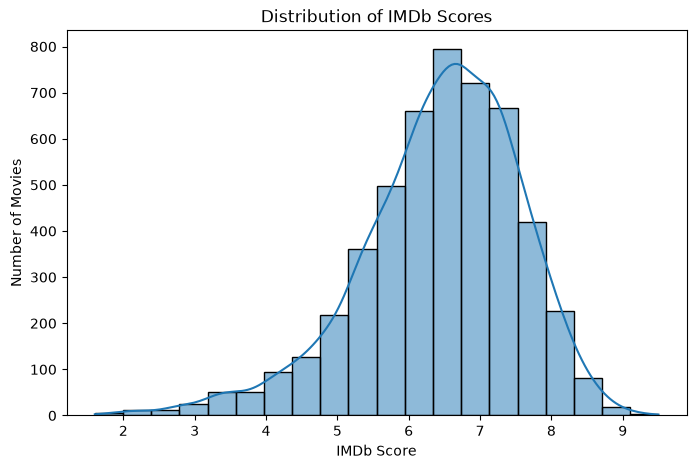

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.histplot(df["imdb_score"], bins=20, kde=True)
plt.title("Distribution of IMDb Scores")
plt.xlabel("IMDb Score")
plt.ylabel("Number of Movies")
plt.show()

most common genres

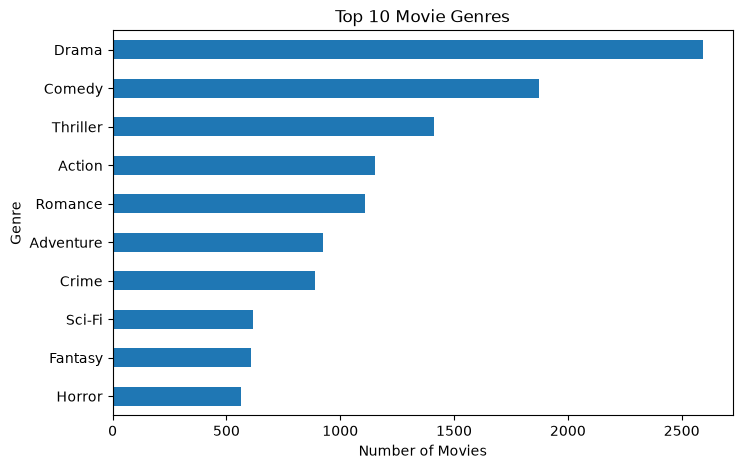

In [11]:
genre_counts = (
    df["genres"]
    .dropna()
    .str.split("|")
    .explode()
    .value_counts()
    .head(10)
)

genre_counts.sort_values().plot(
    kind="barh",
    figsize=(8, 5),
    title="Top 10 Movie Genres"
)

plt.xlabel("Number of Movies")
plt.ylabel("Genre")
plt.show()

Analyze the target classes

Classify
Hit        3589
Average    1413
Flop         41
Name: count, dtype: int64

Class percentages:
Classify
Hit        71.17
Average    28.02
Flop        0.81
Name: proportion, dtype: float64


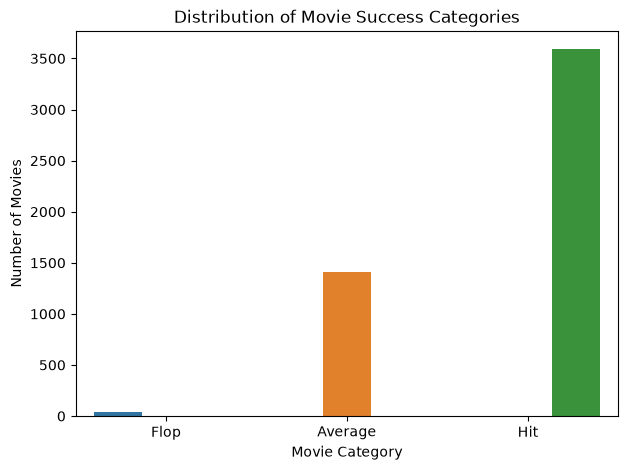

In [12]:
# Create the target variable
df["Classify"] = pd.cut(
    df["imdb_score"],
    bins=[0, 3, 6, 10],
    labels=["Flop", "Average", "Hit"],
    right=False,
    include_lowest=True
)

# Count movies in each class
print(df["Classify"].value_counts())

# Calculate percentages
print("\nClass percentages:")
print((df["Classify"].value_counts(normalize=True) * 100).round(2))

# Visualize class distribution
plt.figure(figsize=(7, 5))
sns.countplot(data=df, x="Classify", hue="Classify", legend=False)

plt.title("Distribution of Movie Success Categories")
plt.xlabel("Movie Category")
plt.ylabel("Number of Movies")
plt.show()

inspect missing values and target validity

In [13]:
# 1. Check IMDb score range
print("Minimum IMDb score:", df["imdb_score"].min())
print("Maximum IMDb score:", df["imdb_score"].max())

# 2. Check missing values
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

# 3. Check missing target labels
print("\nMissing Classify values:", df["Classify"].isna().sum())

# 4. Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Check class counts
print("\nClass distribution:")
print(df["Classify"].value_counts(dropna=False))

Minimum IMDb score: 1.6
Maximum IMDb score: 9.5

Missing values:
gross                      884
budget                     492
aspect_ratio               329
content_rating             303
plot_keywords              153
title_year                 108
director_facebook_likes    104
director_name              104
num_critic_for_reviews      50
actor_3_name                23
actor_3_facebook_likes      23
num_user_for_reviews        21
color                       19
duration                    15
language                    14
dtype: int64

Missing Classify values: 0

Duplicate rows: 45

Class distribution:
Classify
Hit        3589
Average    1413
Flop         41
Name: count, dtype: int64


inspect missing values and target validity

In [14]:
# 1. Check IMDb score range
print("Minimum IMDb score:", df["imdb_score"].min())
print("Maximum IMDb score:", df["imdb_score"].max())

# 2. Check missing values
print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

# 3. Check missing target labels
print("\nMissing Classify values:", df["Classify"].isna().sum())

# 4. Check duplicates
print("\nDuplicate rows:", df.duplicated().sum())

# 5. Check class counts
print("\nClass distribution:")
print(df["Classify"].value_counts(dropna=False))

Minimum IMDb score: 1.6
Maximum IMDb score: 9.5

Missing values:
gross                      884
budget                     492
aspect_ratio               329
content_rating             303
plot_keywords              153
title_year                 108
director_facebook_likes    104
director_name              104
num_critic_for_reviews      50
actor_3_name                23
actor_3_facebook_likes      23
num_user_for_reviews        21
color                       19
duration                    15
language                    14
dtype: int64

Missing Classify values: 0

Duplicate rows: 45

Class distribution:
Classify
Hit        3589
Average    1413
Flop         41
Name: count, dtype: int64


Remove duplicate records

In [15]:
# Remove exact duplicate rows
print("Rows before:", len(df))

df = df.drop_duplicates().copy()

print("Rows after:", len(df))
print("Duplicates remaining:", df.duplicated().sum())

Rows before: 5043
Rows after: 4998
Duplicates remaining: 0


Exclude unsuitable columns

In [16]:
# Columns excluded from the initial model inputs
drop_features = [
    "movie_title",
    "director_name",
    "actor_1_name",
    "actor_2_name",
    "actor_3_name",
    "movie_imdb_link",
    "plot_keywords",
    "imdb_score",
    "Classify"
]

X = df.drop(columns=drop_features)
y = df["Classify"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())

Feature shape: (4998, 20)
Target shape: (4998,)

Feature columns:
['color', 'num_critic_for_reviews', 'duration', 'director_facebook_likes', 'actor_3_facebook_likes', 'actor_1_facebook_likes', 'gross', 'genres', 'num_voted_users', 'cast_total_facebook_likes', 'facenumber_in_poster', 'num_user_for_reviews', 'language', 'country', 'content_rating', 'budget', 'title_year', 'actor_2_facebook_likes', 'aspect_ratio', 'movie_facebook_likes']
